## FACIAL EMOTION RECOGNITION

#### Loading Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

#### Loading Dataset

In [2]:
df = pd.read_csv("fer2013.csv")

print(df.shape)
print(df.head())

(35887, 3)
   emotion                                             pixels     Usage
0        0  70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...  Training
1        0  151 150 147 155 148 133 111 140 170 174 182 15...  Training
2        2  231 212 156 164 174 138 161 173 182 200 106 38...  Training
3        4  24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...  Training
4        6  4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...  Training


#### Converting pixels into images

In [3]:
X = np.array([
    np.fromstring(pixels, dtype=np.uint8, sep=' ')
    for pixels in df["pixels"]
])

X = X.reshape(-1, 48, 48, 1)
X = X.astype("float32") / 255.0

y = df["emotion"].values

print("Images:", X.shape)
print("Labels:", y.shape)

Images: (35887, 48, 48, 1)
Labels: (35887,)


In [4]:
train_idx = df["Usage"] == "Training"
val_idx = df["Usage"] == "PublicTest"
test_idx = df["Usage"] == "PrivateTest"

X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (28709, 48, 48, 1)
Validation: (3589, 48, 48, 1)
Testing: (3589, 48, 48, 1)


#### Emotions Name

In [5]:
emotion_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

#### Displaying some images

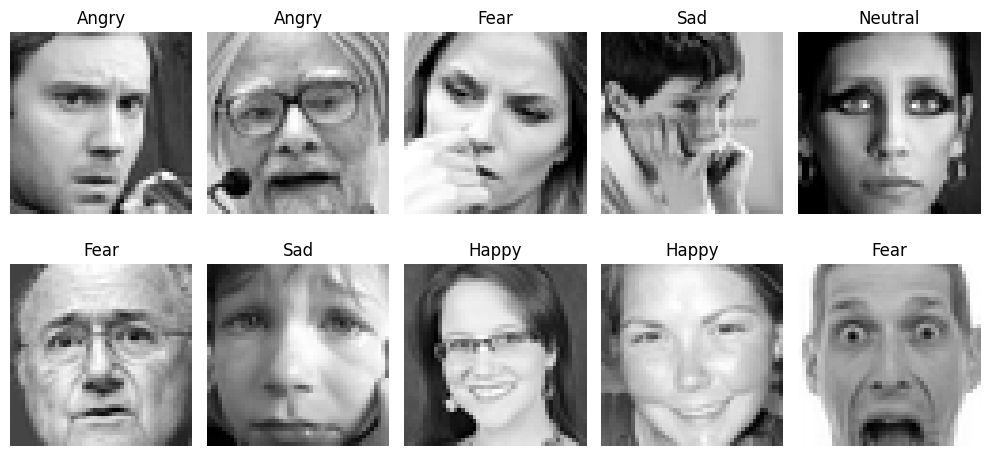

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(emotion_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

#### Data Augmentation

In [7]:
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train)

#### Building CNN Model

In [8]:
model = Sequential([
    
    Conv2D(32, (3, 3), activation="relu", padding="same",
           input_shape=(48, 48, 1)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(7, activation="softmax")
])

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 48, 48, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,983 (433.53 KB)

 Trainable params: 110,535 (431.78 KB)

 Non-trainable params: 448 (1.75 KB)

#### Callbacks

In [10]:
early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

#### Training the Model

In [11]:
history = model.fit(
    datagen.flow(
        X_train,
        y_train,
        batch_size=64
    ),
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 165s 346ms/step - accuracy: 0.2702 - loss: 1.7829 - val_accuracy: 0.1780 - val_loss: 1.9908 - learning_rate: 0.0010
Epoch 2/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 153s 340ms/step - accuracy: 0.3784 - loss: 1.5860 - val_accuracy: 0.3798 - val_loss: 1.5647 - learning_rate: 0.0010
Epoch 3/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 155s 346ms/step - accuracy: 0.4480 - loss: 1.4426 - val_accuracy: 0.3594 - val_loss: 1.6302 - learning_rate: 0.0010
Epoch 4/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 150s 334ms/step - accuracy: 0.4829 - loss: 1.3596 - val_accuracy: 0.4475 - val_loss: 1.4766 - learning_rate: 0.0010
Epoch 5/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 156s 347ms/step - accuracy: 0.5018 - loss: 1.3132 - val_accuracy: 0.4851 - val_loss: 1.3408 - learning_rate: 0.0010
Epoch 6/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 173s 386ms/step - accuracy: 0.5538 - loss: 1.1773 - val_accuracy: 0.5450 - val_loss: 1.1935 - learning_rate: 5.0000e-04
Epoch 10/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 156s 348ms/step - a

#### Testing accuracy

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Test Accuracy: 0.6062970161437988
Test Accuracy (%): 60.62970161437988


#### Plotting Accuracy

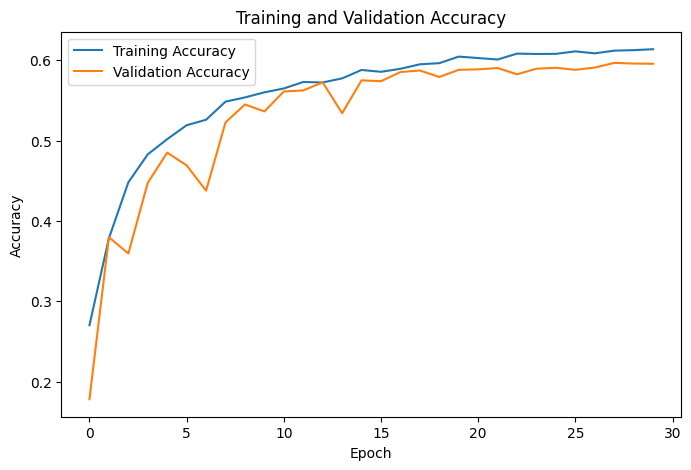

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.show()

#### Plotting Loss

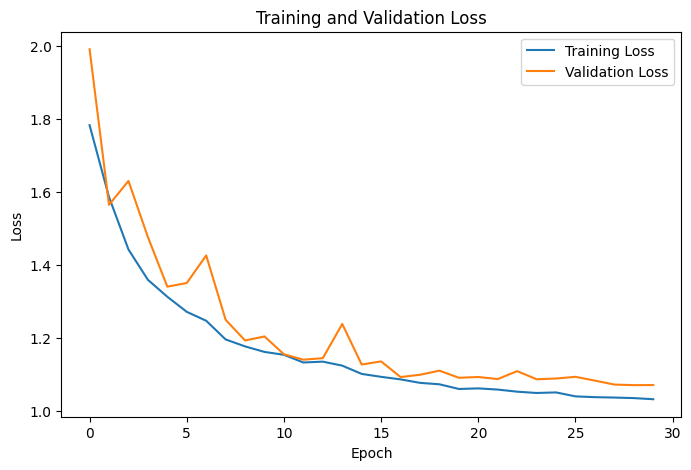

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

#### Testing  Single Image

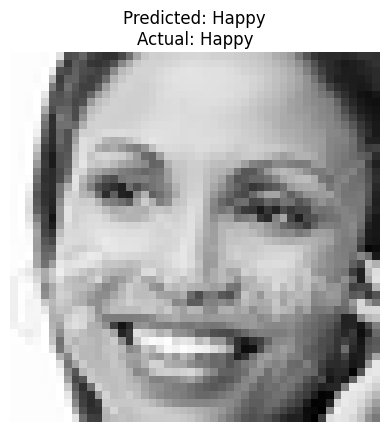

In [18]:
index = 101
image = X_test[index]

prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction)
actual_class = y_test[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {emotion_names[predicted_class]}\n"
    f"Actual: {emotion_names[actual_class]}"
)
plt.axis("off")
plt.show()


#### Saving the model

In [19]:
model.save("facial_emotion_model.keras")

print("Model saved successfully!")

Model saved successfully!


#### Preparing classification report

In [22]:
from sklearn.metrics import classification_report
import numpy as np

y_prob = model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

y_pred = np.argmax(y_prob, axis=1)

In [23]:
print(classification_report(
    y_test,
    y_pred,
    target_names=emotion_names,
    digits=4
))

              precision    recall  f1-score   support

       Angry     0.4716    0.5580    0.5112       491
     Disgust     0.6250    0.0909    0.1587        55
        Fear     0.4626    0.3163    0.3757       528
       Happy     0.8100    0.8635    0.8359       879
         Sad     0.4801    0.4259    0.4514       594
    Surprise     0.7766    0.7188    0.7466       416
     Neutral     0.5304    0.6693    0.5918       626

    accuracy                         0.6063      3589
   macro avg     0.5938    0.5204    0.5245      3589
weighted avg     0.6025    0.6063    0.5968      3589



#### Calculating F1-Score

In [24]:
from sklearn.metrics import f1_score

f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro"
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print(f"Macro F1-Score: {f1_macro:.4f}")
print(f"Weighted F1-Score: {f1_weighted:.4f}")

Macro F1-Score: 0.5245
Weighted F1-Score: 0.5968


#### Live Webcam Demonstration

In [25]:
import cv2
model = tf.keras.models.load_model("facial_emotion_model.keras")

emotion_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.2,
        minNeighbors=5,
        minSize=(60, 60)
    )

    for (x, y, w, h) in faces:

        face = gray[y:y+h, x:x+w]

        face = cv2.resize(face, (48, 48))
        face = face.astype("float32") / 255.0

        face = np.expand_dims(face, axis=-1)
        face = np.expand_dims(face, axis=0)

        prediction = model.predict(face, verbose=0)

        emotion = np.argmax(prediction)
        confidence = np.max(prediction) * 100

        label = f"{emotion_names[emotion]} {confidence:.1f}%"

        cv2.rectangle(
            frame,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            label,
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

    cv2.imshow("Facial Emotion Recognition", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()